# Klasifikasi Relaksasi vs Konsentrasi dengan Muse (Metode Paper)

**Acuan metode:** You, S.D. *Classification of Relaxation and Concentration Mental States with EEG*. Information 2021, 12, 187 (`Document from Ezra.pdf`).
**Alat yang dipakai: hanya Muse.**

**Dataset latih awal:** dataset paper dari github.com/NTUT-LabASPL/EEG (`Run_1` 7 subjek + `Run_2` 10 subjek). Dataset ini direkam dengan alat lain, jadi **selalu dikonversi ke skala Muse dulu** sebelum dipakai. Tidak ada model yang memakai skala asli dataset. Setelah ada rekaman Muse sendiri (`rekam_muse_paper.py`), model pribadi Muse dilatih dari data itu.
**Alat proyek:** **Muse** (4 kanal TP9/AF7/AF8/TP10, 256 Hz, satuan **µV**). Pengambilan data mengacu pada `pengambilan_eeg.py`.

### Alur notebook
1. Memuat dataset paper (Run_1, Run_2).
2. **Mengonversi dataset ke skala Muse.** Batas 1–45 Hz mengikuti bandpass Muse, lalu relative power. Data Muse diproses dengan langkah yang persis sama.
3. Menjalankan **semua eksperimen paper** (Tabel 1–6, Gambar 4–7) pada data yang sudah diskalakan.
4. Melatih **2 algoritma klasifikasi paper (SVM dan BPNN)**, menghitung F1 score keduanya, lalu menyimpan **satu `.pkl` per algoritma**: `models/svm_muse.pkl` dan `models/bpnn_muse.pkl`.
5. Pipeline Muse: µV mentah → spektrogram → skala yang sama → fitur paper → prediksi atau latih model pribadi.

### Apa yang sama dengan paper dan apa yang berbeda
| Tahap | Paper | Notebook ini (Muse) |
|---|---|---|
| Protokol | 10 s: 5 s baseline rileks + 5 s tugas, mata tertutup; con = hitung mundur 5 digit | Sama (`rekam_muse_paper.py`) |
| Jumlah data | 20 con + 20 relax per subjek | Sama (folder > 20 file: ambil 20 pertama **[no-jurnal | terpaksa]**) |
| Representasi | Spektrogram 0.125 s × 0.25 Hz, 0–64 Hz | Sama. Muse dibuat dengan STFT ke format ini **[no-jurnal | terpaksa]** |
| **Skala energi** | Energi asli alat paper | **[no-jurnal | tambahan]** relative power skala Muse: energi ÷ total energi 1–45 Hz per baris |
| Segmen | Detik ke-6 s/d ke-8 | Sama |
| Pers. (1) | y[m,l] = 1/8 Σ x[n,4l] | Sama |
| Fitur | All band; β; α+β; α+β+γ (BW 1/2/4 Hz) | Sama |
| Classifier | SVM RBF γ=8, C=32; BPNN 10 hidden (MSE) | Sama (+ skala min-max [0,1] gaya LIBSVM **[no-jurnal | terpaksa]**) |
| Evaluasi | 70/30, 40 trial, split sama untuk semua metode | Sama |
| Reduksi | PCFA p = 8/6/4 pada β 1 Hz | Sama |
| Model akhir | Individual, α+β+γ 4 Hz | α+β+γ 4 Hz, SVM dan BPNN, 1 `.pkl` per algoritma. Sumber latih: dataset (model umum) **[no-jurnal | terpaksa]**, atau rekaman Muse sendiri (model individual, sesuai paper) |

**Bagian yang tidak tertulis di jurnal.** Semuanya ditandai `[no-jurnal | tambahan]` atau `[no-jurnal | terpaksa]` di notebook dan kode:
* **[no-jurnal | tambahan]** Relative power (bagian 2): konversi skala agar dataset bisa dipakai untuk Muse, sesuai permintaan proyek.
* **[no-jurnal | terpaksa]** (alat Muse) Konversi µV ke spektrogram (STFT, AF7+AF8, filter `pengambilan_eeg.py`), karena Muse tidak mengeluarkan spektrogram seperti alat di jurnal.
* **[no-jurnal | terpaksa]** (jurnal tidak menjelaskan) Penskalaan min-max [0,1] sebelum SVM (LIBSVM), batas gamma band 30–43 Hz, kondisi yang dipakai untuk FA (konsentrasi), dan pengambilan 20 file pertama bila folder berisi lebih dari 20 file.
* **[no-jurnal | tambahan]** Sinyal Muse sintetis (bagian 2 dan 13a): hanya untuk mengecek format dan skala, bukan bagian metode.
* **[no-jurnal | tambahan]** Penjelasan otomatis di setiap output dan sel "Cara membaca output": dokumentasi, bukan metode.
* Selain itu semuanya mengikuti jurnal.

## 0. Persiapan: import library dan konstanta paper

In [1]:
import os                                   # operasi folder & file
import warnings                             # untuk menyembunyikan peringatan konvergensi yang tidak penting
import numpy as np                          # komputasi array
import pandas as pd                         # tabel hasil
import matplotlib.pyplot as plt             # grafik
import joblib                               # menyimpan / memuat model .pkl
from sklearn.base import clone              # menyalin estimator tanpa bobot terlatih

import paper_eeg as P                       # SEMUA metode paper + adapter Muse ada di file ini

warnings.filterwarnings("ignore")           # sembunyikan warning (mis. lbfgs max_iter) agar output rapi
pd.set_option("display.precision", 1)       # tampilkan angka tabel 1 desimal

DATA_DIR = "eeg/extracted"                  # lokasi hasil ekstrak Run_1.zip & Run_2.zip
MODEL_DIR = "models"                        # folder penyimpanan .pkl
os.makedirs(MODEL_DIR, exist_ok=True)       # buat folder models/ bila belum ada

NORM = "relative"                           # skala Muse: relative power 1-45 Hz [no-jurnal | tambahan]
SPLITS = P.trial_splits(n_trials=P.N_TRIALS, seed=0)   # 40 split 70/30 yang SAMA untuk semua metode (paper Sec. 3.3)

print("Konstanta paper yang dipakai:")
print(f"  SVM RBF  : C = {P.SVM_C}, gamma = {P.SVM_GAMMA}")
print(f"  BPNN     : {P.BPNN_HIDDEN} neuron hidden, kriteria MSE")
print(f"  Segmen   : detik ke-{P.SEG_START_SEC + 1} s/d ke-{P.SEG_START_SEC + P.SEG_LEN_SEC} ({P.SEG_LEN_SEC} s)")
print(f"  Evaluasi : {len(SPLITS)} trial, latih {len(SPLITS[0][0])} / uji {len(SPLITS[0][1])} rekaman per subjek")
print(f"  Skala    : NORM = '{NORM}'")

Konstanta paper yang dipakai:
  SVM RBF  : C = 32, gamma = 8
  BPNN     : 10 neuron hidden, kriteria MSE
  Segmen   : detik ke-6 s/d ke-8 (3 s)
  Evaluasi : 40 trial, latih 28 / uji 12 rekaman per subjek
  Skala    : NORM = 'relative'


**Cara membaca output:** baris-baris di atas mengonfirmasi bahwa parameter yang dipakai sama dengan paper: SVM C=32 dan γ=8 (Sec. 3.4), BPNN 10 neuron hidden, segmen detik 6–8 (Sec. 3.3), serta 40 trial dengan 28 rekaman latih (14 con + 14 relax) dan 12 rekaman uji per subjek.

## 1. Memuat dataset paper (Run_1 dan Run_2) sebagai data latih awal

* Run_1: CSV tanpa header, 256 kolom energi (0 sampai 63.75 Hz).
* Run_2: ada header `Time, 0, 0.25, …` dan kolom jam di depan. Kolom jam dibuang.
* Baris kosong `,,,,` di akhir beberapa file (`yo_con`) dilewati. **[no-jurnal | terpaksa]**
* Folder yang berisi lebih dari 20 file (yizhe 40, beberapa subjek Run_2 21–22) diambil **20 pertama** sesuai urutan waktu, karena paper memakai 20 rekaman per kondisi. **[no-jurnal | terpaksa]**

In [2]:
RUNS = {                                                   # dict: nama run -> {subjek -> data}
    "Run_1": P.load_run(f"{DATA_DIR}/Run_1"),              # 7 subjek (S1-S7 di paper)
    "Run_2": P.load_run(f"{DATA_DIR}/Run_2"),              # 10 subjek (S8-S17 di paper)
}
rows = []                                                  # kumpulan ringkasan per subjek
for run, subjects in RUNS.items():                         # loop tiap run
    for s, d in subjects.items():                          # loop tiap subjek
        allrec = d["con"] + d["relax"]                     # gabung 20 con + 20 relax
        rows.append({"run": run, "subjek": s,
                     "n_con": len(d["con"]),               # jumlah rekaman konsentrasi
                     "n_relax": len(d["relax"]),           # jumlah rekaman relaksasi
                     "baris_min": min(x.shape[0] for x in allrec),   # rekaman terpendek (baris @0.125 s)
                     "baris_maks": max(x.shape[0] for x in allrec)}) # rekaman terpanjang
summary = pd.DataFrame(rows)                               # jadikan tabel
summary.insert(0, "S", [f"S{i+1}" for i in range(len(summary))])   # nomor subjek gaya paper
display(summary)                                           # tampilkan tabel
print(f"Penjelasan: total {len(summary)} subjek, semuanya {summary.n_con.min()} con + {summary.n_relax.min()} relax.")
print(f"Rekaman terpendek {summary.baris_min.min()} baris = {summary.baris_min.min()/8:.1f} s, "
      f"cukup untuk segmen detik 6-8 (butuh 64 baris).")

,S,run,subjek,n_con,n_relax,baris_min,baris_maks
0,S1,Run_1,Andy,20,20,80,148
1,S2,Run_1,boyue,20,20,87,97
2,S3,Run_1,icer,20,20,88,107
3,S4,Run_1,wei,20,20,81,104
4,S5,Run_1,yizhe,20,20,84,110
5,S6,Run_1,yo,20,20,84,111
6,S7,Run_1,yuchen,20,20,89,138
7,S8,Run_2,alanchen,20,20,75,92
8,S9,Run_2,alen,20,20,82,93
9,S10,Run_2,chester,20,20,79,87


Penjelasan: total 17 subjek, semuanya 20 con + 20 relax.
Rekaman terpendek 75 baris = 9.4 s, cukup untuk segmen detik 6-8 (butuh 64 baris).


**Cara membaca output:** setiap baris adalah satu subjek. `n_con` dan `n_relax` harus bernilai 20 (sesuai paper). `baris_min` dan `baris_maks` adalah panjang rekaman dalam baris, dengan 1 baris = 0.125 s, jadi sekitar 84 baris ≈ 10.5 s. Andy_relax lebih panjang (~15 s), tetapi yang dipakai hanya detik 6–8, jadi tidak berpengaruh.

## 2. Mengonversi dataset paper ke skala Muse  [no-jurnal | tambahan]

**Masalahnya:** dataset paper direkam dengan alat lain yang memakai satuan energi internal, sedangkan Muse memakai µV²/Hz. Kalau dipakai mentah, model tidak akan cocok dengan data Muse.

**Solusinya, dengan langkah yang sama untuk dataset maupun Muse:**
1. Batasi ke **1–45 Hz**, sama dengan bandpass Muse di `pengambilan_eeg.py`.
2. **Relative power**: x'[n,k] = x[n,k] / Σ_{1≤f<45 Hz} x[n,k]. Setiap baris waktu dibagi total energinya, sehingga hasilnya berupa *proporsi energi* tanpa satuan.
3. Langkah selanjutnya (Pers. 1, fitur, SVM) tetap **persis seperti paper**.

> Langkah ini **tidak ada di jurnal**. Jurnal memakai energi asli alat. Konversi ini ditambahkan hanya agar dataset jurnal bisa dipakai bersama data Muse (µV). Sesudah konversi, akurasi menjadi lebih rendah daripada angka di jurnal.

Satuan dan faktor penguatan alat hilang dalam pembagian ini, sehingga data latih berada pada skala yang sama dengan Muse.

,Dataset (sebelum),Muse asli (µV²/Hz),Dataset (skala Muse),Muse (skala Muse)
rata-rata total energi 1-45 Hz per baris,547.5,133.1,1,1
nilai maksimum,1140,39.89,0.6291,0.1702


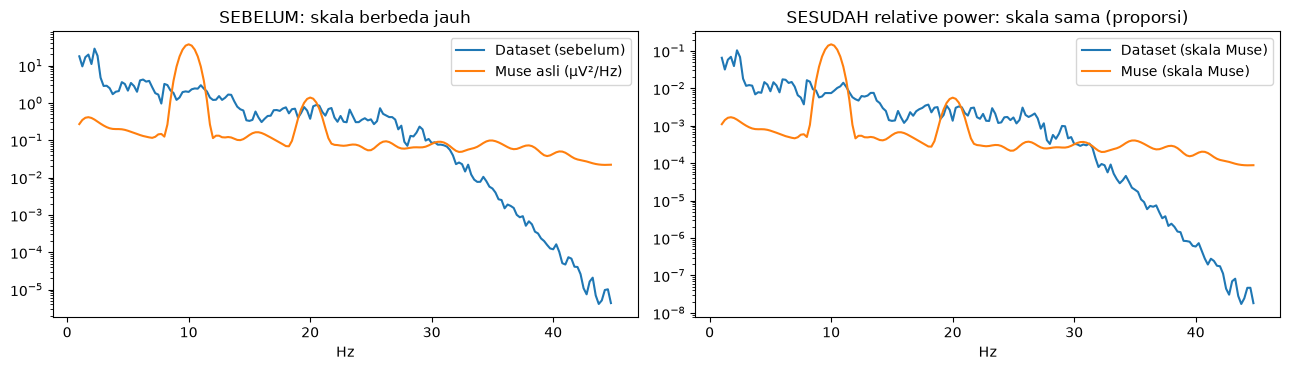

Penjelasan: sebelum konversi, total energi dataset = 4.11x total energi Muse (satuan berbeda).
Sesudah konversi, total 1-45 Hz tiap baris = 1.0 untuk dataset dan Muse, jadi skalanya sama.


In [3]:
spec = RUNS["Run_2"]["max"]["relax"][0]                    # contoh 1 rekaman dataset paper (skala asli, sebelum konversi)
spec_rel = P.normalize_spectrogram(spec, "relative")      # setelah dikonversi ke skala Muse [no-jurnal | tambahan]

# --- [no-jurnal | tambahan] sinyal Muse sintetis (µV) HANYA untuk membandingkan skala; bukan data asli ---
fs = P.MUSE_FS                                             # 256 Hz
t = np.arange(int(11 * fs)) / fs                           # 11 s (protokol paper 10 s + cadangan)
rng = np.random.default_rng(1)                             # seed agar hasil sama tiap dijalankan
def fake_muse(alpha_uv=15, beta_uv=3):
    task = (t >= 5) & (t < 10)                                         # jendela tugas detik 5-10
    x = rng.normal(0, 8, (len(t), 4)).cumsum(0) * 0.05                 # drift lambat (mirip 1/f)
    x += rng.normal(0, 5, (len(t), 4))                                 # noise putih ~5 µV
    x += (alpha_uv * task * np.sin(2 * np.pi * 10 * t))[:, None]       # alpha 10 Hz saat tugas
    x += (beta_uv * task * np.sin(2 * np.pi * 20 * t))[:, None]        # beta 20 Hz saat tugas
    x += 20 * np.sin(2 * np.pi * 50 * t)[:, None]                      # gangguan listrik 50 Hz
    return x                                                           # (n_sampel, 4 kanal) µV
muse_raw = fake_muse()                                                 # buat sinyal uji
muse_spec = P.muse_raw_to_spectrogram(muse_raw, channel_names=P.MUSE_CHANNELS)   # µV -> format spektrogram paper [no-jurnal | terpaksa]
muse_rel = P.normalize_spectrogram(muse_spec, "relative")             # skala bersama [no-jurnal | tambahan]

band = slice(4, 180)                                       # kolom 1-45 Hz (4 kolom per Hz)
stats = pd.DataFrame({
    "Dataset (sebelum)": [spec[:, band].sum(1).mean(), spec[:, band].max()],
    "Muse asli (µV²/Hz)": [muse_spec[:, band].sum(1).mean(), muse_spec[:, band].max()],
    "Dataset (skala Muse)": [spec_rel[:, band].sum(1).mean(), spec_rel[:, band].max()],
    "Muse (skala Muse)": [muse_rel[:, band].sum(1).mean(), muse_rel[:, band].max()],
}, index=["rata-rata total energi 1-45 Hz per baris", "nilai maksimum"])
display(stats.style.format("{:.4g}"))                      # tampilkan perbandingan skala

f = np.arange(256) * 0.25                                  # sumbu frekuensi 0..63.75 Hz
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].semilogy(f[band], spec[40:64, band].mean(0), label="Dataset (sebelum)")             # spektrum rata-rata detik 6-8
ax[0].semilogy(f[band], muse_spec[40:64, band].mean(0), label="Muse asli (µV²/Hz)")
ax[0].set_title("SEBELUM: skala berbeda jauh"); ax[0].set_xlabel("Hz"); ax[0].legend()
ax[1].semilogy(f[band], spec_rel[40:64, band].mean(0), label="Dataset (skala Muse)")
ax[1].semilogy(f[band], muse_rel[40:64, band].mean(0), label="Muse (skala Muse)")
ax[1].set_title("SESUDAH relative power: skala sama (proporsi)"); ax[1].set_xlabel("Hz"); ax[1].legend()
plt.tight_layout(); plt.show()

ratio_before = spec[:, band].sum(1).mean() / muse_spec[:, band].sum(1).mean()
print(f"Penjelasan: sebelum konversi, total energi dataset = {ratio_before:.3g}x total energi Muse (satuan berbeda).")
print("Sesudah konversi, total 1-45 Hz tiap baris = 1.0 untuk dataset dan Muse, jadi skalanya sama.")

**Cara membaca output:**
* **Tabel:** kolom "sebelum" dan "Muse asli" menunjukkan skala yang sangat berbeda. Kolom "skala Muse" bernilai rata-rata total = 1 untuk keduanya, artinya skala sudah sama.
* **Grafik kiri:** spektrum kedua alat terpisah jauh secara vertikal karena satuannya berbeda.
* **Grafik kanan:** setelah diskalakan, kedua spektrum berada pada rentang yang sama. Yang tersisa hanya perbedaan *bentuk* spektrum, yaitu informasi yang memang dicari (misalnya proporsi alpha vs beta).
* Sinyal Muse di sini sintetis, hanya untuk menunjukkan skala. Puncak 10 Hz dan 20 Hz adalah sinyal uji, dan garis 50 Hz hilang karena notch filter.

## 3. Spektrogram dan segmen yang dipakai (seperti Gambar 2 di paper)

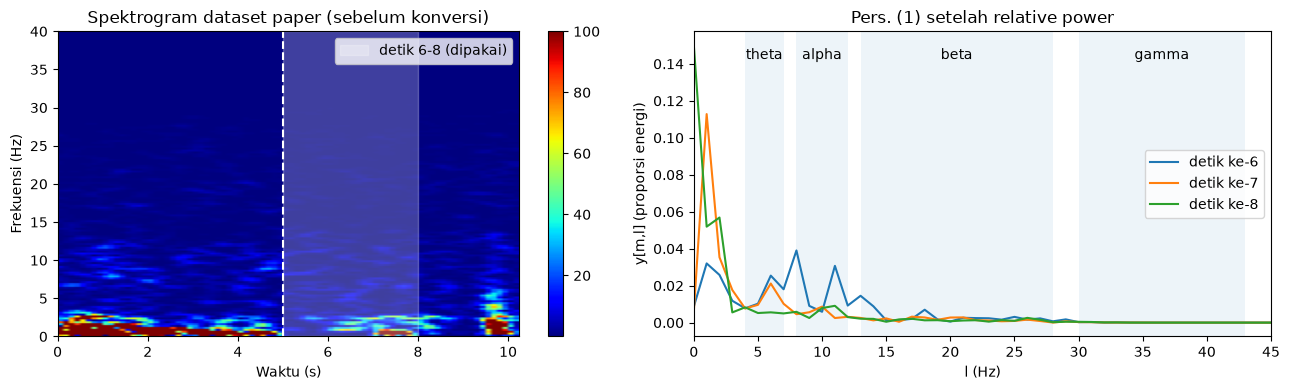

Penjelasan: energi rekaman ini (sebelum konversi) maks 2510.0, mean 5.98, std 64.58. Sebagian besar sel kecil dan hanya sedikit yang besar, sama dengan pengamatan paper (Sec. 3.2).
Grafik kanan: y[m,l] = rata-rata 8 baris per detik pada kolom l Hz. Inilah dasar semua fitur.


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
show = np.minimum(spec[:, :160].T, 100)                    # potong energi >100 jadi 100 (sama seperti Gbr. 2)
im = ax[0].imshow(show, aspect="auto", origin="lower", extent=[0, spec.shape[0] / 8, 0, 40], cmap="jet")
ax[0].axvspan(5, 8, color="white", alpha=0.25, label="detik 6-8 (dipakai)")   # tandai segmen klasifikasi
ax[0].axvline(5, color="w", ls="--")                       # batas baseline (0-5 s) dan tugas (5-10 s)
ax[0].set_xlabel("Waktu (s)"); ax[0].set_ylabel("Frekuensi (Hz)"); ax[0].legend(loc="upper right")
ax[0].set_title("Spektrogram dataset paper (sebelum konversi)"); plt.colorbar(im, ax=ax[0])
y = P.segment_y(spec_rel)                                  # Pers. (1) pada data yang sudah diskalakan
for m in range(3):                                         # 3 detik: ke-6, ke-7, ke-8
    ax[1].plot(np.arange(64), y[m], label=f"detik ke-{m+6}")
for lo, hi, c in [(4, 7, "theta"), (8, 12, "alpha"), (13, 28, "beta"), (30, 43, "gamma")]:
    ax[1].axvspan(lo, hi, alpha=0.08)                      # arsir rentang band paper
    ax[1].text((lo + hi) / 2, y.max() * 0.95, c, ha="center")
ax[1].set_xlim(0, 45); ax[1].set_xlabel("l (Hz)"); ax[1].set_ylabel("y[m,l] (proporsi energi)")
ax[1].set_title("Pers. (1) setelah relative power"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Penjelasan: energi rekaman ini (sebelum konversi) maks {spec.max():.1f}, mean {spec.mean():.2f}, std {spec.std():.2f}. "
      "Sebagian besar sel kecil dan hanya sedikit yang besar, sama dengan pengamatan paper (Sec. 3.2).")
print("Grafik kanan: y[m,l] = rata-rata 8 baris per detik pada kolom l Hz. Inilah dasar semua fitur.")

**Cara membaca output:** grafik kiri adalah spektrogram satu rekaman. Garis putus-putus pada 5 s memisahkan baseline dan tugas, dan area terang (5–8 s) adalah bagian yang dipakai untuk klasifikasi. Grafik kanan adalah hasil Pers. (1): tiga kurva untuk tiga detik, dengan sumbu-y berupa proporsi energi per Hz.

## 4. Jenis fitur paper (Sec. 3.3) dan dimensinya

Rentang beta_1 (13–20 Hz), beta_2 (21–28 Hz), β, α+β, dan α+β+γ diambil langsung dari jurnal. Batas theta (4–7), alpha (8–12), dan gamma (30–43 Hz) untuk *All band energy* tidak ditulis eksplisit di Sec. 3.3, jadi diambil dari definisi band Sec. 1 jurnal (gamma dibatasi 43 Hz = batas fitur α+β+γ). **[no-jurnal | terpaksa]**

In [5]:
dims = pd.DataFrame([{"fitur": fs_,                                      # nama jenis fitur
                      "rentang": ("theta/alpha/beta1/beta2/gamma" if fs_ == "all_band"
                                  else "%d-%d Hz" % P.BAND_RANGES[fs_.split("|")[0]]),
                      "dimensi (3 detik)": P.extract_features(spec, fs_, NORM).size}   # panjang vektor fitur
                     for fs_ in P.FEATURE_SETS])
display(dims)
print("Penjelasan: dimensi = 3 detik x jumlah nilai per detik. Contoh β 1 Hz: 16 nilai (13-28 Hz) x 3 = 48,")
print("persis sama dengan paper. α+β+γ 4 Hz (rekomendasi paper) = 9 kelompok x 3 = 27 dimensi.")

,fitur,rentang,dimensi (3 detik)
0,all_band,theta/alpha/beta1/beta2/gamma,15
1,beta|1Hz,13-28 Hz,48
2,beta|2Hz,13-28 Hz,24
3,beta|4Hz,13-28 Hz,12
4,alpha+beta|1Hz,9-28 Hz,60
5,alpha+beta|2Hz,9-28 Hz,30
6,alpha+beta|4Hz,9-28 Hz,15
7,alpha+beta+gamma|1Hz,9-43 Hz,105
8,alpha+beta+gamma|2Hz,9-43 Hz,54
9,alpha+beta+gamma|4Hz,9-43 Hz,27


Penjelasan: dimensi = 3 detik x jumlah nilai per detik. Contoh β 1 Hz: 16 nilai (13-28 Hz) x 3 = 48,
persis sama dengan paper. α+β+γ 4 Hz (rekomendasi paper) = 9 kelompok x 3 = 27 dimensi.


**Cara membaca output:** tabel berisi 10 jenis fitur. Makin kecil bandwidth (1 Hz), makin banyak dimensinya.

## 5. Fungsi evaluasi (protokol paper)

Setiap kombinasi subjek × classifier × fitur dijalankan **40 trial** dengan split acak 70/30. TP/TN/FP/FN dijumlahkan per subjek, lalu dihitung **mean dan std antar subjek**, sama dengan format Tabel 2–5. Kelas positif = konsentrasi, sehingga Sensitivity = benar con dan Specificity = benar relax.

Sebelum SVM/BPNN, fitur diskalakan min-max [0,1] (fit hanya pada data latih), mengikuti alur LIBSVM. Jurnal tidak menyebut penskalaan, padahal tanpa itu γ=8 tidak berfungsi. **[no-jurnal | terpaksa]**

In [6]:
CLASSIFIERS = {"SVM": P.make_svm, "BPNN": P.make_bpnn}    # dua classifier paper
_cache = {}                                                # simpan hasil agar tidak dihitung ulang

def run_eval(run, feature_set, clf, estimator=None, norm=NORM, start_sec=P.SEG_START_SEC):
    # Evaluasi model INDIVIDUAL: satu model per subjek, 40 trial, return tabel metrik per subjek
    key = (run, feature_set, clf, norm, start_sec)
    if key not in _cache:
        est = estimator if estimator is not None else CLASSIFIERS[clf]()   # estimator baru
        res = {}
        for s, d in RUNS[run].items():                                     # tiap subjek
            X, y = P.subject_matrix(d, feature_set, norm, start_sec)       # fitur 40 rekaman
            res[s] = P.evaluate_individual(X, y, est, SPLITS)              # 40 trial 70/30
        _cache[key] = pd.DataFrame(res).T
    return _cache[key]

def table(runs, feature_sets, clf, label=lambda f: f, **kw):
    # Ringkas ke format tabel paper: mean & std antar subjek
    out = []
    for fs_ in feature_sets:
        df = pd.concat([run_eval(r, fs_, clf, **kw) for r in runs])
        out.append({"fitur": label(fs_),
                    "Sens mean": df.sensitivity.mean(), "Sens std": df.sensitivity.std(ddof=0),
                    "Spec mean": df.specificity.mean(), "Spec std": df.specificity.std(ddof=0),
                    "Acc mean": df.accuracy.mean(), "Acc std": df.accuracy.std(ddof=0),
                    "F1": df.f1.mean()})
    return pd.DataFrame(out).set_index("fitur")

pretty = lambda f: (f.replace("alpha+beta+gamma", "α+β+γ").replace("alpha+beta", "α+β")
                     .replace("beta", "β only").replace("|", ", "))      # nama fitur gaya paper
FS9 = [f for f in P.FEATURE_SETS if f != "all_band"]                     # 9 fitur Tabel 2-5
both = ["Run_1", "Run_2"]
print("Fungsi evaluasi siap. Contoh 1 split: latih index", SPLITS[0][0][:5], "... uji", SPLITS[0][1][:3], "...")
print("Penjelasan: index 0-19 = rekaman con, 20-39 = rekaman relax. Tiap trial mengambil 14+14 latih dan 6+6 uji.")

Fungsi evaluasi siap. Contoh 1 split: latih index [ 4 19  6  2 13] ... uji [18 17 14] ...
Penjelasan: index 0-19 = rekaman con, 20-39 = rekaman relax. Tiap trial mengambil 14+14 latih dan 6+6 uji.


**Cara membaca output:** contoh index split menunjukkan rekaman mana yang masuk data latih dan data uji pada trial pertama.

## 6. Eksperimen I: model umum vs model individual (Run_1, All band energy). Tabel 1
* **Model umum:** satu SVM dari data latih semua subjek, lalu menguji semua data uji.
* **Model individual:** satu SVM per subjek. Split per trial sama dengan model umum.

In [7]:
def eval_generic(run, feature_set, norm=NORM):
    mats = {s: P.subject_matrix(d, feature_set, norm) for s, d in RUNS[run].items()}   # fitur tiap subjek
    counts = np.zeros(4, int)                                                          # TP, TN, FP, FN
    for tr, te in SPLITS:                                                              # 40 trial
        Xtr = np.vstack([X[tr] for X, _ in mats.values()]); ytr = np.concatenate([y[tr] for _, y in mats.values()])
        Xte = np.vstack([X[te] for X, _ in mats.values()]); yte = np.concatenate([y[te] for _, y in mats.values()])
        counts += P.confusion(yte, P.make_svm().fit(Xtr, ytr).predict(Xte))           # 1 SVM untuk semua
    return P.metrics_from_counts(*counts)

g = eval_generic("Run_1", "all_band")["accuracy"]                     # akurasi model umum
i = run_eval("Run_1", "all_band", "SVM").accuracy.mean()              # rata-rata akurasi model individual
t1 = pd.DataFrame({"Accuracy (ini)": [g, i], "Accuracy (paper)": [57.1, 74.4]},
                  index=["All band energy, SVM umum", "All band energy, SVM individual"])
display(t1)
print(f"Penjelasan: model individual {i - g:+.1f} poin dibanding model umum "
      f"({'sesuai' if i > g else 'TIDAK sesuai'} kesimpulan paper bahwa model individual lebih baik).")

,Accuracy (ini),Accuracy (paper)
"All band energy, SVM umum",61.3,57.1
"All band energy, SVM individual",61.3,74.4


Penjelasan: model individual -0.1 poin dibanding model umum (TIDAK sesuai kesimpulan paper bahwa model individual lebih baik).


**Cara membaca output:** bandingkan kolom *ini* dengan *paper*. Yang penting adalah arah perbandingannya: model individual lebih tinggi dari model umum. Inilah alasan model Muse dibuat per pengguna.

## 7. Eksperimen II: rentang band dan bandwidth berbeda (Run_1). Tabel 2 (SVM) dan Tabel 3 (BPNN)

In [8]:
t2 = table(["Run_1"], FS9, "SVM", pretty)                 # 9 fitur x SVM, 7 subjek Run_1
display(t2)
b = t2["Acc mean"].idxmax()
print(f"Penjelasan: fitur SVM terbaik di Run_1 = {b} ({t2.loc[b, 'Acc mean']:.1f}%). "
      f"Paper Tabel 2: terbaik α+β+γ 2 Hz (81.9%).")

,Sens mean,Sens std,Spec mean,Spec std,Acc mean,Acc std,F1
fitur,,,,,,,
"β only, 1Hz",66.6,32.0,44.6,31.5,55.6,4.2,55.4
"β only, 2Hz",66.4,29.1,52.7,26.0,59.6,6.1,58.9
"β only, 4Hz",66.0,9.5,57.3,14.1,61.7,8.2,63.3
"α+β, 1Hz",67.0,35.9,45.3,36.5,56.1,4.7,55.0
"α+β, 2Hz",68.6,30.1,49.9,31.2,59.2,6.3,59.2
"α+β, 4Hz",70.5,15.4,57.0,22.1,63.7,7.8,65.6
"α+β+γ, 1Hz",63.9,37.8,47.4,35.9,55.7,3.8,52.7
"α+β+γ, 2Hz",66.0,32.2,49.3,31.1,57.7,5.5,56.7
"α+β+γ, 4Hz",70.2,20.0,50.8,17.9,60.5,5.1,62.5


Penjelasan: fitur SVM terbaik di Run_1 = α+β, 4Hz (63.7%). Paper Tabel 2: terbaik α+β+γ 2 Hz (81.9%).


In [9]:
t3 = table(["Run_1"], FS9, "BPNN", pretty)                # 9 fitur x BPNN
display(t3)
diff = (t2["Acc mean"] - t3["Acc mean"]).mean()
print(f"Penjelasan: rata-rata SVM - BPNN = {diff:+.1f} poin. Paper: SVM lebih tinggi daripada BPNN (Tabel 2 vs 3).")

,Sens mean,Sens std,Spec mean,Spec std,Acc mean,Acc std,F1
fitur,,,,,,,
"β only, 1Hz",65.2,11.3,62.5,9.0,63.9,9.6,64.2
"β only, 2Hz",65.5,12.5,62.3,6.7,63.9,8.2,64.1
"β only, 4Hz",63.4,12.7,60.2,9.0,61.8,9.3,62.1
"α+β, 1Hz",66.8,13.9,65.4,11.2,66.1,11.3,66.1
"α+β, 2Hz",63.8,11.2,60.5,9.6,62.1,8.5,62.5
"α+β, 4Hz",63.0,12.8,60.8,7.9,61.9,8.7,61.9
"α+β+γ, 1Hz",72.9,15.5,75.6,10.4,74.3,10.8,73.4
"α+β+γ, 2Hz",71.2,13.2,71.9,10.4,71.6,10.6,71.2
"α+β+γ, 4Hz",70.2,10.9,65.8,8.8,68.0,9.3,68.5


Penjelasan: rata-rata SVM - BPNN = -7.1 poin. Paper: SVM lebih tinggi daripada BPNN (Tabel 2 vs 3).


**Cara membaca output:** Sens = persentase rekaman con yang benar, Spec = persentase rekaman relax yang benar, Acc = akurasi total, dan std = variasi antar subjek. Std yang besar berarti hasil antar subjek sangat berbeda (efek *BCI-illiteracy* yang juga dibahas paper).

### Gambar 4: akurasi tiap subjek Run_1 untuk tiap jenis fitur (SVM)

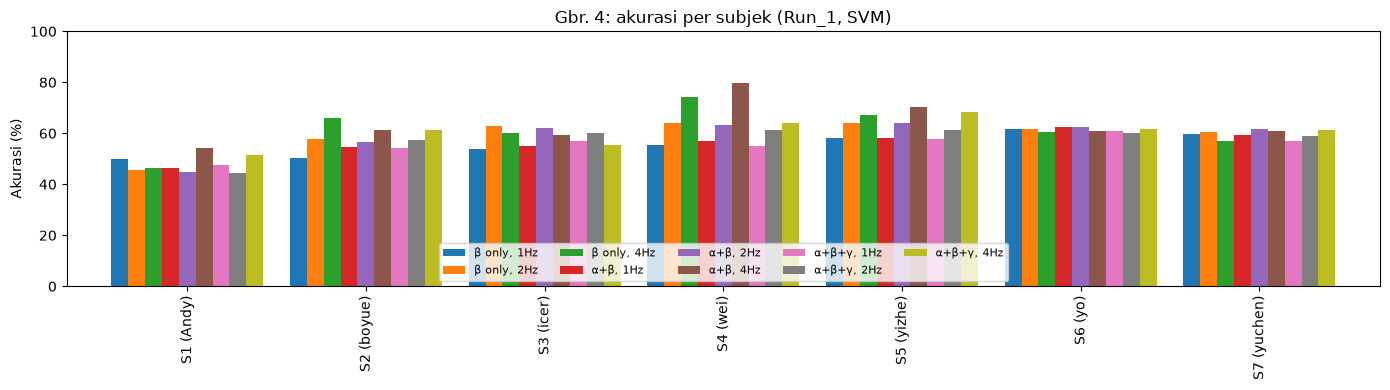

Penjelasan: fitur terbaik tiap subjek: {'S1 (Andy)': 'α+β, 4Hz', 'S2 (boyue)': 'β only, 4Hz', 'S3 (icer)': 'β only, 2Hz', 'S4 (wei)': 'α+β, 4Hz', 'S5 (yizhe)': 'α+β, 4Hz', 'S6 (yo)': 'α+β, 1Hz', 'S7 (yuchen)': 'α+β, 2Hz'}
Sama dengan paper: fitur terbaik berbeda-beda antar subjek.


In [10]:
acc = pd.DataFrame({pretty(f): run_eval("Run_1", f, "SVM").accuracy for f in FS9})   # subjek x fitur
acc.index = [f"S{k+1} ({s})" for k, s in enumerate(acc.index)]
acc.plot.bar(figsize=(14, 4), width=0.85); plt.ylim(0, 100); plt.ylabel("Akurasi (%)")
plt.legend(ncol=5, fontsize=8, loc="lower center"); plt.title("Gbr. 4: akurasi per subjek (Run_1, SVM)")
plt.tight_layout(); plt.show()
print("Penjelasan: fitur terbaik tiap subjek:", acc.idxmax(axis=1).to_dict())
print("Sama dengan paper: fitur terbaik berbeda-beda antar subjek.")

**Cara membaca output:** setiap kelompok batang adalah satu subjek dan setiap warna adalah satu jenis fitur. Subjek dengan semua batang rendah kemungkinan termasuk *BCI-illiterate*.

## 8. Eksperimen III: reduksi dimensi Factor Analysis / PCFA (Run_1). Gambar 5
Fitur penuh = β only 1 Hz (16 nilai per detik). Untuk p = 8, 6, 4: C = (1/42) Σ bᵢbᵢᵀ dari 14 rekaman latih × 3 detik **kondisi konsentrasi** (jurnal hanya menyebut "satu kondisi", tanpa menyebut yang mana: **[no-jurnal | terpaksa]**), lalu L = [√λ e], f = (LᵀL)⁻¹Lᵀt, dan tiga f digabung (3p dimensi), lalu SVM.

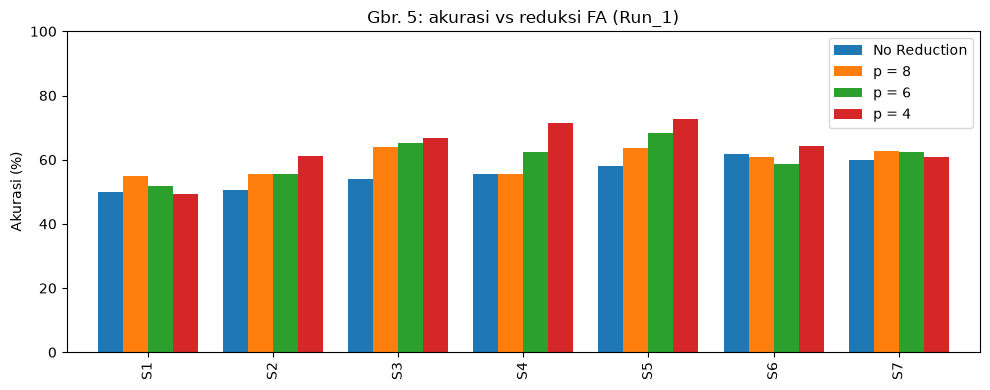

,mean,std,paper mean,paper std
FA p=4,63.8,7.3,77.9,4.9
β only 4 Hz,61.7,8.2,77.0,12.9


Penjelasan: FA p=4 dan β 4 Hz sama-sama berdimensi 12. Paper: FA sedikit lebih tinggi dan std-nya jauh lebih kecil.
Di sini: std FA = 7.3 vs std β 4 Hz = 8.2.


In [11]:
FA_P = [8, 6, 4]                                           # tingkat reduksi paper
def fa_eval(run):
    out = {"No Reduction": run_eval(run, "beta|1Hz", "SVM").accuracy}               # tanpa reduksi
    for p in FA_P:
        out[f"p = {p}"] = run_eval(run, "beta|1Hz", f"FA{p}", estimator=P.FASVM(p=p)).accuracy   # PCFA + SVM
    return pd.DataFrame(out)

fa1 = fa_eval("Run_1")
ax = fa1.set_index(pd.Index([f"S{k+1}" for k in range(len(fa1))])).plot.bar(figsize=(10, 4), width=0.8)
ax.set_ylim(0, 100); ax.set_ylabel("Akurasi (%)"); ax.set_title("Gbr. 5: akurasi vs reduksi FA (Run_1)")
plt.tight_layout(); plt.show()
b4 = run_eval("Run_1", "beta|4Hz", "SVM").accuracy
display(pd.DataFrame({"mean": [fa1["p = 4"].mean(), b4.mean()], "std": [fa1["p = 4"].std(ddof=0), b4.std(ddof=0)],
                      "paper mean": [77.9, 77.0], "paper std": [4.9, 12.9]}, index=["FA p=4", "β only 4 Hz"]))
print("Penjelasan: FA p=4 dan β 4 Hz sama-sama berdimensi 12. Paper: FA sedikit lebih tinggi dan std-nya jauh lebih kecil.")
print(f"Di sini: std FA = {fa1['p = 4'].std(ddof=0):.1f} vs std β 4 Hz = {b4.std(ddof=0):.1f}.")

**Cara membaca output:** grafik membandingkan akurasi per subjek pada berbagai tingkat reduksi. Tabel membandingkan FA p=4 dengan β 4 Hz (dimensi sama). Fokus paper ada pada *std* yang lebih kecil, artinya hasil lebih stabil antar subjek.

## 9. Uji reproduksi (Run_2, 10 subjek baru). Tabel 4 + FA

In [12]:
t4 = table(["Run_2"], FS9, "SVM", pretty)                 # 9 fitur x SVM, 10 subjek Run_2
display(t4)
b = t4["Acc mean"].idxmax()
print(f"Penjelasan: fitur terbaik Run_2 = {b} ({t4.loc[b, 'Acc mean']:.1f}%). Paper Tabel 4: β only 4 Hz (87.7%).")
print(f"Run_2 rata-rata {t4['Acc mean'].mean():.1f}% vs Run_1 {t2['Acc mean'].mean():.1f}% "
      "(paper: Run_2 juga lebih tinggi).")

,Sens mean,Sens std,Spec mean,Spec std,Acc mean,Acc std,F1
fitur,,,,,,,
"β only, 1Hz",68.8,37.9,51.4,32.6,60.1,4.1,57.1
"β only, 2Hz",74.2,30.9,56.9,21.0,65.5,9.1,64.9
"β only, 4Hz",84.2,14.8,66.9,14.1,75.6,10.0,77.2
"α+β, 1Hz",68.4,38.9,49.3,34.3,58.9,3.6,55.7
"α+β, 2Hz",75.7,29.8,51.7,21.2,63.7,6.8,64.6
"α+β, 4Hz",84.0,18.7,63.1,15.7,73.5,8.1,75.2
"α+β+γ, 1Hz",68.3,39.1,46.5,34.8,57.4,2.6,54.8
"α+β+γ, 2Hz",72.6,33.9,51.0,28.7,61.8,5.2,61.2
"α+β+γ, 4Hz",77.8,30.8,59.0,24.8,68.4,8.9,67.4


Penjelasan: fitur terbaik Run_2 = β only, 4Hz (75.6%). Paper Tabel 4: β only 4 Hz (87.7%).
Run_2 rata-rata 65.0% vs Run_1 58.9% (paper: Run_2 juga lebih tinggi).


In [13]:
fa2 = fa_eval("Run_2")
b4 = run_eval("Run_2", "beta|4Hz", "SVM").accuracy
display(pd.DataFrame({"mean": [fa2["p = 4"].mean(), b4.mean()], "std": [fa2["p = 4"].std(ddof=0), b4.std(ddof=0)],
                      "paper mean": [80.2, 87.7], "paper std": [6.4, 11.1]}, index=["FA p=4", "β only 4 Hz"]))
print("Penjelasan: paper Run_2 menunjukkan FA lebih rendah dari β 4 Hz tetapi std-nya lebih kecil.")

,mean,std,paper mean,paper std
FA p=4,75.9,8.8,80.2,6.4
β only 4 Hz,75.6,10.0,87.7,11.1


Penjelasan: paper Run_2 menunjukkan FA lebih rendah dari β 4 Hz tetapi std-nya lebih kecil.


**Cara membaca output:** sama dengan bagian 7 dan 8, tetapi pada 10 subjek baru. Tujuannya mengecek apakah pola hasil Run_1 berulang (reproducible).

## 10. Gabungan kedua Run (17 subjek). Tabel 5, Tabel 6, Gambar 6, Gambar 7

In [14]:
cols = ["Acc mean", "Sens mean", "Spec mean", "F1"]
t5 = pd.concat({"SVM": table(both, FS9, "SVM", pretty)[cols],
                "BPNN": table(both, FS9, "BPNN", pretty)[cols]}, axis=1)   # gabungan 17 subjek
display(t5)
r = t5[("SVM", "Acc mean")]
print(f"Penjelasan: rekomendasi paper α+β+γ 4 Hz = {r['α+β+γ, 4Hz']:.1f}% (paper 83.0%). "
      f"Terbaik di sini: {r.idxmax()} ({r.max():.1f}%).")

SVM                               BPNN                      \
            Acc mean Sens mean Spec mean    F1 Acc mean Sens mean Spec mean   
fitur                                                                         
β only, 1Hz     58.2      67.9      48.6  56.4     70.0      69.3      70.6   
β only, 2Hz     63.1      71.0      55.1  62.5     69.3      69.4      69.2   
β only, 4Hz     69.9      76.7      63.0  71.5     69.4      67.9      71.0   
α+β, 1Hz        57.7      67.8      47.7  55.4     71.0      70.1      71.9   
α+β, 2Hz        61.9      72.8      50.9  62.4     69.0      69.3      68.7   
α+β, 4Hz        69.5      78.4      60.6  71.2     72.1      72.5      71.8   
α+β+γ, 1Hz      56.7      66.5      46.9  54.0     78.1      77.0      79.2   
α+β+γ, 2Hz      60.1      69.9      50.3  59.3     74.7      73.4      76.1   
α+β+γ, 4Hz      65.2      74.7      55.7  65.4     72.1      72.1      72.0   

                   
               F1  
fitur              
β only, 1Hz  69.8  
β only, 2Hz  69.2  
β only, 4Hz  69.0  
α+β, 1Hz     70.5  
α+β, 2Hz     69.1  
α+β, 4Hz     72.2  
α+β+γ, 1Hz   77.5  
α+β+γ, 2Hz   74.2  
α+β+γ, 4Hz   72.1

Penjelasan: rekomendasi paper α+β+γ 4 Hz = 65.2% (paper 83.0%). Terbaik di sini: β only, 4Hz (69.9%).


**Cara membaca output:** tabel merangkum ke-17 subjek untuk SVM dan BPNN. Paper memakai tabel ini untuk menyimpulkan bahwa bandwidth lebar (4 Hz) cenderung lebih baik.

,S8,S17
SVM,β,β
BPNN,αβγ,αβ


Penjelasan (Tabel 6): 2 subjek punya akurasi SVM > 85%. Band terbaik SVM dan BPNN sama pada 0% subjek (paper: 50%). Jadi pilihan classifier mempengaruhi band terbaik.


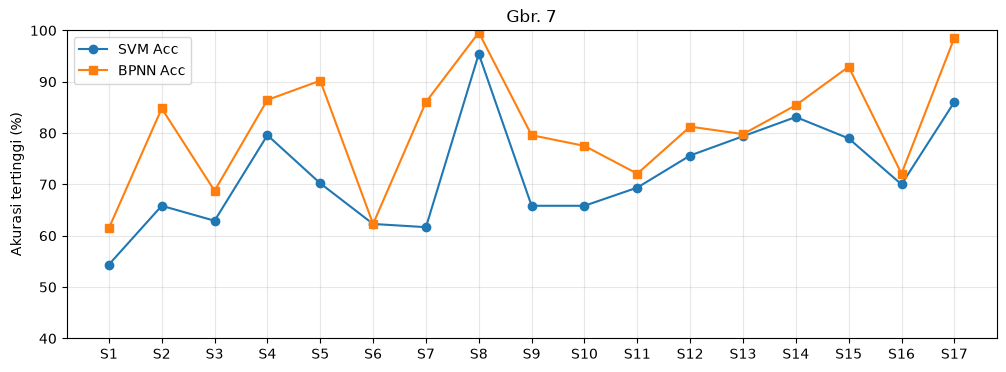

Penjelasan (Gbr. 7): korelasi akurasi tertinggi SVM vs BPNN antar subjek = 0.77. Paper: keduanya konsisten, jadi subjek yang rendah di satu classifier juga rendah di classifier lain (BCI-illiteracy).


In [15]:
def best(clf):
    a = pd.concat([pd.DataFrame({f: run_eval(r, f, clf).accuracy for f in FS9}) for r in both])
    a.index = [f"S{k+1}" for k in range(len(a))]
    return a                                                         # subjek x fitur
a_svm, a_bp = best("SVM"), best("BPNN")
band = lambda f: {"beta": "β", "alpha+beta": "αβ", "alpha+beta+gamma": "αβγ"}[f.split("|")[0]]
sel = a_svm.max(axis=1) > 85                                         # paper: hanya subjek dgn akurasi SVM > 85 %
t6 = pd.DataFrame({"SVM": a_svm[sel].idxmax(axis=1).map(band), "BPNN": a_bp[sel].idxmax(axis=1).map(band)}).T
display(t6)
cons = (t6.loc["SVM"] == t6.loc["BPNN"]).mean() * 100 if sel.any() else float("nan")
print(f"Penjelasan (Tabel 6): {sel.sum()} subjek punya akurasi SVM > 85%. Band terbaik SVM dan BPNN "
      f"sama pada {cons:.0f}% subjek (paper: 50%). Jadi pilihan classifier mempengaruhi band terbaik.")
plt.figure(figsize=(12, 4))
plt.plot(a_svm.index, a_svm.max(axis=1), "o-", label="SVM Acc"); plt.plot(a_bp.index, a_bp.max(axis=1), "s-", label="BPNN Acc")
plt.ylim(40, 100); plt.ylabel("Akurasi tertinggi (%)"); plt.legend(); plt.grid(alpha=.3); plt.title("Gbr. 7"); plt.show()
print(f"Penjelasan (Gbr. 7): korelasi akurasi tertinggi SVM vs BPNN antar subjek = "
      f"{np.corrcoef(a_svm.max(axis=1), a_bp.max(axis=1))[0, 1]:.2f}. Paper: keduanya konsisten, "
      "jadi subjek yang rendah di satu classifier juga rendah di classifier lain (BCI-illiteracy).")

**Cara membaca output:** Tabel 6 menunjukkan band terbaik per subjek (hanya subjek dengan akurasi > 85%). Gambar 7 adalah akurasi tertinggi tiap subjek untuk kedua classifier. Jika kedua garis bergerak bersamaan, berarti rendah atau tingginya akurasi lebih ditentukan oleh subjek daripada oleh classifier.

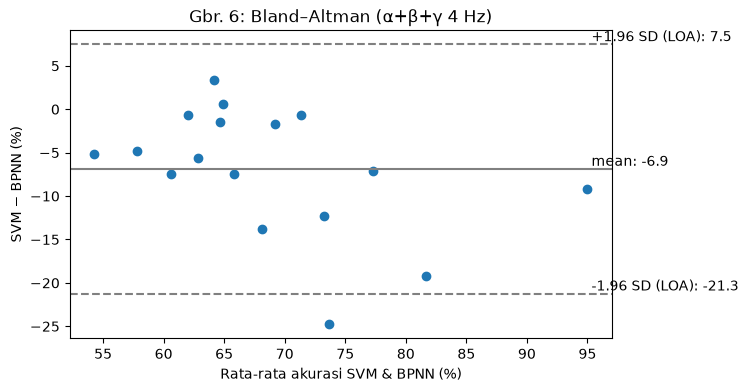

Penjelasan: titik di atas 0 berarti subjek itu lebih akurat dengan SVM. Rata-rata selisih = -6.9% (paper: SVM ~1.5% lebih tinggi). 2/17 subjek lebih baik dengan SVM.


In [16]:
f_ = "alpha+beta+gamma|4Hz"
s_ = pd.concat([run_eval(r, f_, "SVM").accuracy for r in both]).values     # akurasi SVM per subjek
b_ = pd.concat([run_eval(r, f_, "BPNN").accuracy for r in both]).values    # akurasi BPNN per subjek
mean_, diff_ = (s_ + b_) / 2, s_ - b_                                       # sumbu Bland-Altman
md_, sd_ = diff_.mean(), diff_.std(ddof=1)
plt.figure(figsize=(7, 4)); plt.scatter(mean_, diff_)
for v, lab in [(md_, "mean"), (md_ + 1.96 * sd_, "+1.96 SD (LOA)"), (md_ - 1.96 * sd_, "-1.96 SD (LOA)")]:
    plt.axhline(v, ls="-" if lab == "mean" else "--", c="gray"); plt.text(mean_.max(), v, f" {lab}: {v:.1f}", va="bottom")
plt.xlabel("Rata-rata akurasi SVM & BPNN (%)"); plt.ylabel("SVM − BPNN (%)"); plt.title("Gbr. 6: Bland–Altman (α+β+γ 4 Hz)"); plt.show()
print(f"Penjelasan: titik di atas 0 berarti subjek itu lebih akurat dengan SVM. Rata-rata selisih = {md_:+.1f}% "
      f"(paper: SVM ~1.5% lebih tinggi). {int((diff_ > 0).sum())}/{len(diff_)} subjek lebih baik dengan SVM.")

**Cara membaca output:** setiap titik adalah satu subjek. Garis tengah adalah rata-rata selisih SVM − BPNN, dan garis putus-putus adalah batas kesepakatan (±1.96 SD).

## 11. Ringkasan: hasil (skala Muse) vs paper, akurasi SVM dan BPNN rata-rata

In [17]:
paper_t2 = [78.2, 79.2, 77.0, 74.5, 76.8, 79.1, 79.0, 81.9, 79.3]           # Tabel 2 paper (Run_1)
paper_t4 = [84.6, 85.3, 87.7, 76.8, 81.3, 83.2, 79.4, 85.0, 85.6]           # Tabel 4 paper (Run_2)
paper_t5 = [82.0, 82.8, 83.3, 75.9, 79.4, 81.5, 79.3, 83.7, 83.0]           # Tabel 5 paper (gabungan)
cmp = pd.DataFrame({"Run_1 (ini)": t2["Acc mean"].values, "Run_1 paper": paper_t2,
                    "Run_2 (ini)": t4["Acc mean"].values, "Run_2 paper": paper_t4,
                    "Gabungan (ini, skala Muse)": t5[("SVM", "Acc mean")].values,
                    "Gabungan paper": paper_t5,
                    "BPNN gabungan (ini)": t5[("BPNN", "Acc mean")].values,                      # Tabel 5 BPNN
                    "BPNN gabungan paper": [76.2, 77.5, 80.0, 75.7, 77.9, 80.9, 76.7, 80.2, 81.5]}, index=t2.index)
display(cmp)
print("Penjelasan: semua kolom '(ini)' memakai dataset yang sudah dikonversi ke skala Muse (relative power).")
print("Selisih dengan paper = efek konversi skala Muse (bagian 2).")

,Run_1 (ini),Run_1 paper,Run_2 (ini),Run_2 paper,"Gabungan (ini, skala Muse)",Gabungan paper,BPNN gabungan (ini),BPNN gabungan paper
fitur,,,,,,,,
"β only, 1Hz",55.6,78.2,60.1,84.6,58.2,82.0,70.0,76.2
"β only, 2Hz",59.6,79.2,65.5,85.3,63.1,82.8,69.3,77.5
"β only, 4Hz",61.7,77.0,75.6,87.7,69.9,83.3,69.4,80.0
"α+β, 1Hz",56.1,74.5,58.9,76.8,57.7,75.9,71.0,75.7
"α+β, 2Hz",59.2,76.8,63.7,81.3,61.9,79.4,69.0,77.9
"α+β, 4Hz",63.7,79.1,73.5,83.2,69.5,81.5,72.1,80.9
"α+β+γ, 1Hz",55.7,79.0,57.4,79.4,56.7,79.3,78.1,76.7
"α+β+γ, 2Hz",57.7,81.9,61.8,85.0,60.1,83.7,74.7,80.2
"α+β+γ, 4Hz",60.5,79.3,68.4,85.6,65.2,83.0,72.1,81.5


Penjelasan: semua kolom '(ini)' memakai dataset yang sudah dikonversi ke skala Muse (relative power).
Selisih dengan paper = efek konversi skala Muse (bagian 2).


**Cara membaca output:** bandingkan setiap kolom *ini* (skala Muse) dengan kolom *paper* di sebelahnya. Akurasi di sini lebih rendah dari paper karena konversi ke skala Muse menghilangkan informasi energi absolut, (bagian 2).

## 12. Model akhir: 2 algoritma klasifikasi paper (SVM dan BPNN), 1 `.pkl` per algoritma

Paper memakai **2 algoritma klasifikasi** (Sec. 3.4): **SVM** (RBF, γ=8, C=32, LIBSVM) dan **BPNN** (3 layer, 10 neuron hidden, MSE). Fitur yang dipakai adalah rekomendasi paper (Sec. 5): **α+β+γ 4 Hz**, *"satisfactory accuracy … for both classifiers"*.

| File | Algoritma |
|---|---|
| `models/svm_muse.pkl` | SVM RBF γ=8, C=32 |
| `models/bpnn_muse.pkl` | BPNN 10 hidden, MSE |

**Sumber data latih (`SUMBER_LATIH`):**
* `"dataset"` (default): 17 subjek × 40 rekaman dataset paper, dikonversi ke skala Muse. Ini **model umum** seperti Eksperimen I paper. **[no-jurnal | terpaksa]** Alasannya: paper menganjurkan model individual, tetapi model individual hanya cocok untuk orang yang datanya dipakai melatih. Pengguna Muse bukan salah satu dari 17 subjek dataset, dan permintaan proyek adalah satu `.pkl` per algoritma. Jadi satu-satunya model dari dataset yang bisa dipakai pengguna baru adalah model umum.
* `"muse:<nama>"`: dilatih dari rekaman Muse Anda (`data_muse/<nama>/`). Ini **model individual**, persis anjuran paper, dan file `.pkl`-nya tetap 2.

**F1 score** dihitung dengan Pers. (2) paper: F1 = 2TP / (2TP + FP + FN), kelas positif = konsentrasi. Ada dua cara evaluasi paper:
1. **Individual** (Tabel 2–5): 40 trial 70/30 per subjek, dirata-rata antar subjek.
2. **Umum** (Tabel 1): 1 model dari data latih semua subjek, diuji pada data uji semua subjek, 40 trial dengan split yang sama.

In [18]:
FEAT = P.RECOMMENDED_FEATURE            # "alpha+beta+gamma|4Hz" (rekomendasi paper Sec. 5)
SUMBER_LATIH = "dataset"                # "dataset" atau "muse:<nama>" (lihat penjelasan di atas)
ALGO = {"SVM": P.make_svm, "BPNN": P.make_bpnn}                       # 2 algoritma klasifikasi paper
PKL = {"SVM": f"{MODEL_DIR}/svm_muse.pkl", "BPNN": f"{MODEL_DIR}/bpnn_muse.pkl"}   # 1 .pkl per algoritma

def eval_generic_clf(runs, make_est):
    # Evaluasi MODEL UMUM gaya Eksperimen I: 1 model dari data latih semua subjek, 40 trial split sama
    mats = [P.subject_matrix(d, FEAT, NORM) for r in runs for d in RUNS[r].values()]
    counts = np.zeros(4, int)                                                   # TP, TN, FP, FN
    for tr, te in SPLITS:
        Xtr = np.vstack([X[tr] for X, _ in mats]); ytr = np.concatenate([y[tr] for _, y in mats])
        Xte = np.vstack([X[te] for X, _ in mats]); yte = np.concatenate([y[te] for _, y in mats])
        counts += P.confusion(yte, make_est().fit(Xtr, ytr).predict(Xte))
    return P.metrics_from_counts(*counts)

# ---- 1) F1 score kedua algoritma (protokol paper, data dataset skala Muse) ----
rows = []
for name, make_est in ALGO.items():
    ind = pd.concat([run_eval(r, FEAT, name) for r in both])                   # individual, 17 subjek
    gen = eval_generic_clf(both, make_est)                                     # umum, 17 subjek
    rows.append({"algoritma": name,
                 "F1 individual": ind.f1.mean(), "Acc individual": ind.accuracy.mean(),
                 "Sens individual": ind.sensitivity.mean(), "Spec individual": ind.specificity.mean(),
                 "F1 umum": gen["f1"], "Acc umum": gen["accuracy"],
                 "Sens umum": gen["sensitivity"], "Spec umum": gen["specificity"]})
f1_table = pd.DataFrame(rows).set_index("algoritma")
f1_table["F1 paper (individual, T5)"] = [84.6, 84.0]                          # Tabel 5 paper, α+β+γ 4 Hz
display(f1_table)

# ---- 2) Data latih model akhir ----
if SUMBER_LATIH == "dataset":
    X_fin = np.vstack([P.subject_matrix(d, FEAT, NORM)[0] for r in both for d in RUNS[r].values()])
    y_fin = np.concatenate([P.subject_matrix(d, FEAT, NORM)[1] for r in both for d in RUNS[r].values()])
    trained_on = [s for r in both for s in RUNS[r]]
    f1_ref = {k: f1_table.loc[k, "F1 umum"] for k in ALGO}                    # F1 yang relevan = model umum
else:
    nama = SUMBER_LATIH.split(":", 1)[1]
    dm = P.load_muse_subject(os.path.join("data_muse", nama))                 # rekaman Muse µV -> spektrogram
    n = min(len(dm["con"]), len(dm["relax"]))
    X_fin, y_fin = P.subject_matrix({"con": dm["con"][:n], "relax": dm["relax"][:n]}, FEAT, NORM)
    trained_on = [f"muse/{nama}"]
    sp = P.trial_splits(n_per_state=n)
    f1_ref = {k: P.evaluate_individual(X_fin, y_fin, ALGO[k](), sp)["f1"] for k in ALGO}   # 40 trial data Muse

# ---- 3) Latih & simpan 1 .pkl per algoritma ----
for name, make_est in ALGO.items():
    model = P.PaperEEGModel(estimator=make_est().fit(X_fin, y_fin), feature_set=FEAT, norm=NORM,
                            device="muse", trained_on=trained_on,
                            info={"algoritma": name, "sumber_latih": SUMBER_LATIH, "n_samples": int(len(y_fin)),
                                  "f1_40trial": round(float(f1_ref[name]), 1),
                                  "param": ({"C": P.SVM_C, "gamma": P.SVM_GAMMA} if name == "SVM"
                                            else {"hidden": P.BPNN_HIDDEN, "loss": "MSE"})})
    joblib.dump(model, PKL[name])                                              # simpan .pkl

for fn in sorted(os.listdir(MODEL_DIR)):                                       # hanya 2 .pkl yang dipakai
    if fn.endswith(".pkl") and f"{MODEL_DIR}/{fn}" not in PKL.values():
        os.remove(f"{MODEL_DIR}/{fn}")                                         # hapus .pkl lama
for name, path in PKL.items():
    print(f"  {path:24s} {os.path.getsize(path) // 1024:4d} KB  | {name} | latih {len(y_fin)} rekaman | "
          f"F1 40-trial = {f1_ref[name]:.1f}")

best = f1_table["F1 individual"].idxmax()
print(f"\nPenjelasan: F1 individual SVM = {f1_table.loc['SVM','F1 individual']:.1f}, BPNN = {f1_table.loc['BPNN','F1 individual']:.1f} "
      f"(paper: SVM 84.6, BPNN 84.0). Di data skala Muse, yang lebih tinggi adalah {best}.")
print(f"F1 model umum SVM = {f1_table.loc['SVM','F1 umum']:.1f}, BPNN = {f1_table.loc['BPNN','F1 umum']:.1f}. "
      "Untuk SUMBER_LATIH='dataset', nilai inilah perkiraan kualitas .pkl yang tersimpan.")
print(f"Sumber latih .pkl: {SUMBER_LATIH}. Folder models/ hanya berisi 2 file: svm_muse.pkl dan bpnn_muse.pkl.")

,F1 individual,Acc individual,Sens individual,Spec individual,F1 umum,Acc umum,Sens umum,Spec umum,"F1 paper (individual, T5)"
algoritma,,,,,,,,,
SVM,65.4,65.2,74.7,55.7,64.3,60.9,70.4,51.5,84.6
BPNN,72.1,72.1,72.1,72.0,57.6,58.2,56.8,59.7,84.0


  models/svm_muse.pkl       140 KB  | SVM | latih 680 rekaman | F1 40-trial = 64.3
  models/bpnn_muse.pkl       13 KB  | BPNN | latih 680 rekaman | F1 40-trial = 57.6

Penjelasan: F1 individual SVM = 65.4, BPNN = 72.1 (paper: SVM 84.6, BPNN 84.0). Di data skala Muse, yang lebih tinggi adalah BPNN.
F1 model umum SVM = 64.3, BPNN = 57.6. Untuk SUMBER_LATIH='dataset', nilai inilah perkiraan kualitas .pkl yang tersimpan.
Sumber latih .pkl: dataset. Folder models/ hanya berisi 2 file: svm_muse.pkl dan bpnn_muse.pkl.


**Cara membaca output:**
* **Tabel F1:** satu baris per algoritma. Kolom *individual* menggunakan protokol Tabel 2–5 paper (1 model per subjek). Kolom *umum* menggunakan protokol Tabel 1 (1 model untuk semua subjek), jenis model yang disimpan saat `SUMBER_LATIH = "dataset"`. Kolom terakhir adalah F1 paper sebagai pembanding.
* **Daftar file:** dua `.pkl` (SVM dan BPNN) beserta F1 40-trial yang relevan dengan sumber latihnya.
* F1 lebih rendah dari paper karena konversi ke skala Muse **[no-jurnal | tambahan]** (bagian 2).

### Uji memuat ulang kedua `.pkl` dan memprediksi

In [19]:
models = {name: joblib.load(path) for name, path in PKL.items()}      # muat svm_muse.pkl & bpnn_muse.pkl
for state in ("con", "relax"):
    f_ = RUNS["Run_2"]["max"][f"files_{state}"][0]                     # 1 file contoh
    S = P.read_powerspec_csv(f_)                                      # spektrogram (dikonversi ke skala Muse di dalam model)
    pred = {name: m.predict_spectrogram(S) for name, m in models.items()}
    print(f"  label asli {state:5s} | SVM: {pred['SVM']:5s} | BPNN: {pred['BPNN']:5s} | {os.path.relpath(f_, DATA_DIR)}")
display(pd.DataFrame({name: m.info for name, m in models.items()}).T)
m_svm, m_bpnn = models["SVM"], models["BPNN"]                         # dipakai di bagian 13
print("Penjelasan: kedua model berhasil dimuat ulang dan mengeluarkan label 'con'/'relax'.")
print("Konversi skala Muse (relative power) dijalankan otomatis di dalam model (atribut .norm).")
print("Tabel: info yang tersimpan di setiap .pkl (algoritma, sumber latih, F1 40-trial, parameter paper).")

  label asli con   | SVM: con   | BPNN: con   | Run_2/max_con/170611103832.powerspec.csv
  label asli relax | SVM: relax | BPNN: relax | Run_2/max_relax/170611103058.powerspec.csv


,algoritma,sumber_latih,n_samples,f1_40trial,param
SVM,SVM,dataset,680,64.3,"{'C': 32, 'gamma': 8}"
BPNN,BPNN,dataset,680,57.6,"{'hidden': 10, 'loss': 'MSE'}"


Penjelasan: kedua model berhasil dimuat ulang dan mengeluarkan label 'con'/'relax'.
Konversi skala Muse (relative power) dijalankan otomatis di dalam model (atribut .norm).
Tabel: info yang tersimpan di setiap .pkl (algoritma, sumber latih, F1 40-trial, parameter paper).


**Cara membaca output:** baris prediksi membandingkan label asli dengan prediksi SVM dan BPNN. Tabel berisi metadata yang ikut tersimpan di setiap `.pkl`.

## 13. Muse: pipeline yang sama untuk data mikrovolt

**[no-jurnal | terpaksa]** (alat Muse). Alur: µV mentah (TP9, AF7, AF8, TP10 @ 256 Hz) → filter 1–45 Hz + notch 50 Hz (`pengambilan_eeg.py`) → STFT dengan jendela Hann 1 s, hop 0.125 s, nfft 1024 (bin 0.25 Hz) → rata-rata energi AF7 & AF8 → spektrogram berformat `*.powerspec.csv` → **relative power [no-jurnal | tambahan]** → Pers. (1) → α+β+γ 4 Hz → **SVM** (γ=8, C=32) dan **BPNN** (10 hidden, MSE).

Perekaman: `python rekam_muse_paper.py --nama <nama>` (20 relax + 20 con, mata tertutup).

### 13a. [no-jurnal | tambahan] Uji pipeline dengan sinyal Muse sintetis (cek format dan skala, bukan data asli)

Spektrogram Muse : (81, 256) -> baris tiap 0.125 s, 256 kolom 0-63.75 Hz
Spektrogram data : (82, 256) -> format sama (jumlah baris tergantung durasi rekaman)
Fitur Muse  : (27,), rentang 0.0001 - 0.0569
Fitur dataset : (27,), rentang 0.0000 - 0.0137
Prediksi sinyal sintetis -> SVM: con | BPNN: relax


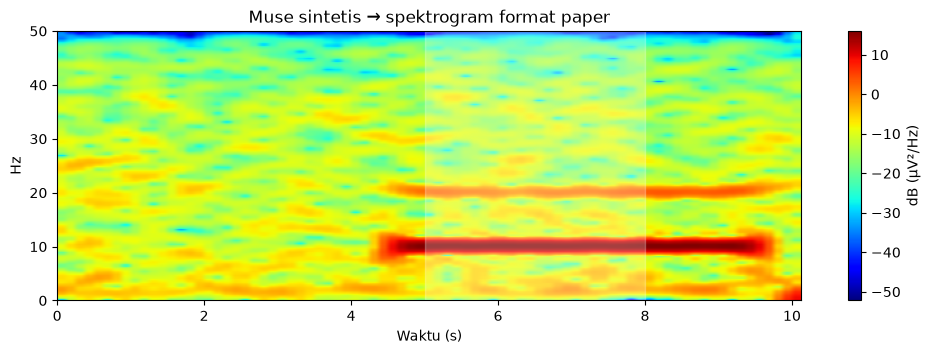

Penjelasan: fitur Muse dan fitur dataset sama-sama berupa proporsi energi (0-1), jadi bisa masuk
ke model yang sama. Prediksi untuk sinyal sintetis tidak bermakna; ini hanya bukti bahwa pipeline berjalan.


In [20]:
print("Spektrogram Muse :", muse_spec.shape, "-> baris tiap 0.125 s, 256 kolom 0-63.75 Hz")
print("Spektrogram data :", spec.shape, "-> format sama (jumlah baris tergantung durasi rekaman)")
fm = P.extract_features(muse_spec, FEAT, NORM)                # fitur Muse (skala relative)
fn = P.extract_features(spec, FEAT, NORM)                     # fitur dataset (skala Muse)
print(f"Fitur Muse  : {fm.shape}, rentang {fm.min():.4f} - {fm.max():.4f}")
print(f"Fitur dataset : {fn.shape}, rentang {fn.min():.4f} - {fn.max():.4f}")
print("Prediksi sinyal sintetis -> SVM:", m_svm.predict_spectrogram(muse_spec), "| BPNN:", m_bpnn.predict_spectrogram(muse_spec))
plt.figure(figsize=(12, 3.5))
plt.imshow(10 * np.log10(muse_spec[:, :200].T + 1e-12), aspect="auto", origin="lower",
           extent=[0, muse_spec.shape[0] / 8, 0, 50], cmap="jet")
plt.axvspan(5, 8, color="w", alpha=.25); plt.colorbar(label="dB (µV²/Hz)")
plt.xlabel("Waktu (s)"); plt.ylabel("Hz"); plt.title("Muse sintetis → spektrogram format paper"); plt.show()
print("Penjelasan: fitur Muse dan fitur dataset sama-sama berupa proporsi energi (0-1), jadi bisa masuk")
print("ke model yang sama. Prediksi untuk sinyal sintetis tidak bermakna; ini hanya bukti bahwa pipeline berjalan.")

**Cara membaca output:** bentuk array harus sama (256 kolom), dan rentang fitur Muse dan dataset harus berada pada orde yang sama, yaitu bukti skalanya sudah sama. Pada spektrogram, pita 10 Hz dan 20 Hz muncul setelah detik 5 (sinyal uji), dan garis 50 Hz hilang karena notch filter.

### 13b. Rekaman Muse pengguna: F1 kedua algoritma dan melatih ulang `.pkl`
Setiap folder `data_muse/<nama>/` (berisi `con/` dan `relax/`) dievaluasi dengan protokol paper, yaitu 40 trial 70/30 untuk **SVM dan BPNN** (model individual, sesuai anjuran paper). Kedua `.pkl` dari bagian 12 juga diuji langsung pada data ini.

Untuk menjadikan `.pkl` sebagai model pribadi Muse (anjuran paper), ubah `SUMBER_LATIH = "muse:<nama>"` di bagian 12, lalu jalankan ulang notebook. File yang terbentuk tetap hanya `svm_muse.pkl` dan `bpnn_muse.pkl`.

In [21]:
MUSE_DIR = "data_muse"
muse_subjects = (sorted(d for d in os.listdir(MUSE_DIR) if os.path.isdir(os.path.join(MUSE_DIR, d)))
                 if os.path.isdir(MUSE_DIR) else [])                       # daftar pengguna Muse
if not muse_subjects:
    print("Belum ada rekaman Muse di data_muse/.")
    print("Rekam dulu :  python rekam_muse_paper.py --nama <nama>   (20 relax + 20 con, mata tertutup)")
    print('Lalu set SUMBER_LATIH = "muse:<nama>" di bagian 12 dan jalankan ulang notebook.')
muse_report = {}
for name in muse_subjects:
    d = P.load_muse_subject(os.path.join(MUSE_DIR, name))                 # µV -> spektrogram format paper
    n = min(len(d["con"]), len(d["relax"]))                                # jumlah seimbang per kondisi
    if n < 5:
        print(f"{name}: data kurang (con={len(d['con'])}, relax={len(d['relax'])}), dilewati"); continue
    X, y = P.subject_matrix({"con": d["con"][:n], "relax": d["relax"][:n]}, FEAT, NORM)   # fitur paper
    sp = P.trial_splits(n_per_state=n)                                     # 40 trial 70/30
    row = {"n_per_kondisi": n}
    for algo, make_est in ALGO.items():
        cv = P.evaluate_individual(X, y, make_est(), sp)                   # model individual Muse
        cnt = P.confusion(y, models[algo].estimator.predict(X))            # .pkl bagian 12 diuji langsung
        row[f"F1 individual {algo}"] = cv["f1"]; row[f"Acc individual {algo}"] = cv["accuracy"]
        row[f"F1 {os.path.basename(PKL[algo])}"] = P.metrics_from_counts(*cnt)["f1"]
    muse_report[name] = row
if muse_report:
    display(pd.DataFrame(muse_report).T)
    print("Penjelasan: 'F1 individual' = F1 protokol paper bila model dilatih dari rekaman Muse orang itu sendiri.")
    print("'F1 svm_muse.pkl / bpnn_muse.pkl' = F1 model dari bagian 12 bila langsung dipakai pada rekaman ini.")

Belum ada rekaman Muse di data_muse/.
Rekam dulu :  python rekam_muse_paper.py --nama <nama>   (20 relax + 20 con, mata tertutup)
Lalu set SUMBER_LATIH = "muse:<nama>" di bagian 12 dan jalankan ulang notebook.


**Cara membaca output:** jika belum ada rekaman, sel menampilkan petunjuk. Jika sudah ada, setiap baris adalah satu pengguna Muse, berisi F1 kedua algoritma (model individual) dan F1 kedua `.pkl` pada rekaman itu.

### 13c. Contoh inferensi untuk satu rekaman Muse baru
```python
import joblib, paper_eeg as P
model = joblib.load("models/svm_muse.pkl")             # atau models/bpnn_muse.pkl
raw, ch = P.read_muse_csv("rekaman_baru.csv")           # 10-11 s, protokol yang sama
S = P.muse_raw_to_spectrogram(raw, channel_names=ch)    # µV -> spektrogram format paper
print(model.predict_spectrogram(S))                     # relative power otomatis, hasil 'con' / 'relax'
```

In [22]:
# [no-jurnal | tambahan] demo format CSV Muse memakai sinyal sintetis (bukan bagian metode)
demo_csv = os.path.join(MODEL_DIR, "_contoh_format_muse.csv")                # file CSV contoh sementara
pd.DataFrame(np.c_[t, muse_raw], columns=["timestamp"] + P.MUSE_CHANNELS).to_csv(demo_csv, index=False)
raw2, ch2 = P.read_muse_csv(demo_csv)                                         # baca seperti file hasil rekam
S2 = P.muse_raw_to_spectrogram(raw2, channel_names=ch2)                       # µV -> spektrogram format paper
print(f"CSV terbaca: {raw2.shape} sampel x kanal {ch2} -> spektrogram {S2.shape}")
for name, path in PKL.items():
    m = joblib.load(path)                                                     # muat .pkl
    print(f"{os.path.basename(path)} -> prediksi: {m.predict_spectrogram(S2)}")
os.remove(demo_csv)                                                           # hapus file contoh
print("Penjelasan: alur inferensi dari file CSV Muse berjalan untuk kedua .pkl. Prediksi sinyal sintetis tidak bermakna.")

CSV terbaca: (2816, 4) sampel x kanal ['TP9', 'AF7', 'AF8', 'TP10'] -> spektrogram (81, 256)
svm_muse.pkl -> prediksi: con
bpnn_muse.pkl -> prediksi: relax
Penjelasan: alur inferensi dari file CSV Muse berjalan untuk kedua .pkl. Prediksi sinyal sintetis tidak bermakna.


**Cara membaca output:** baris pertama memastikan format CSV Muse terbaca (4 kanal µV). Baris berikutnya adalah prediksi masing-masing `.pkl` (SVM dan BPNN).